# Step 4: Data Visualisation Dashboard & Econometric Conclusion

**Project Question:** *After allowing for magnitude and depth, how much does a country's income explain earthquake deaths?*

**Visual Design & Gestalt Principles Used:**
- **Greyscale Readability:** All plots pair luminance-ordered palettes (dark navy `#1B365D` to light gold `#F0E442` / muted grey `#B0B0B0`) with distinct marker shapes, line styles, or bar borders so every series remains distinguishable in black-and-white print.
- **Gestalt Principles:** We apply **Proximity & Alignment** (shared axes across comparison panels), **Common Region** (shaded physical/economic regime zones), **Continuity** (OLS regression trendlines), and **Figure–Ground Focal Highlight** (using one crimson-orange accent `#D55E00` to isolate errors, disagreements, and low-income vulnerability against muted grey background data).

In [2]:
import os, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
os.makedirs("reports/figures", exist_ok=True)

# Load final master clean dataset
master_path = sorted(glob.glob("clean/earthquakes_master_2000_2025*.parquet"))[-1]
df = pd.read_parquet(master_path)

# Create clean analytical columns
INCOME_ORDER = ["Low income", "Lower middle income", "Upper middle income", "High income"]
df["log10_deaths"] = np.log10(df["deaths_final"] + 1.0)
df["log10_gdp"] = np.log10(df["gdp_per_capita_ppp_constant_2021"])
df["depth_zone"] = pd.cut(df["depth"], bins=[-1, 70, 300, 800], labels=["Shallow (0–70 km)", "Intermediate (70–300 km)", "Deep (>300 km)"])

print(f"Loaded Master Clean Dataset: {df.shape} | Onshore with GDP & Income Group: {df['income_group'].isin(INCOME_ORDER).sum()}")

Loaded Master Clean Dataset: (3360, 24) | Onshore with GDP & Income Group: 1905


## Plot 1: Data Cleaning Impact — Before vs. After Spatiotemporal Deduplication & Depth Curation

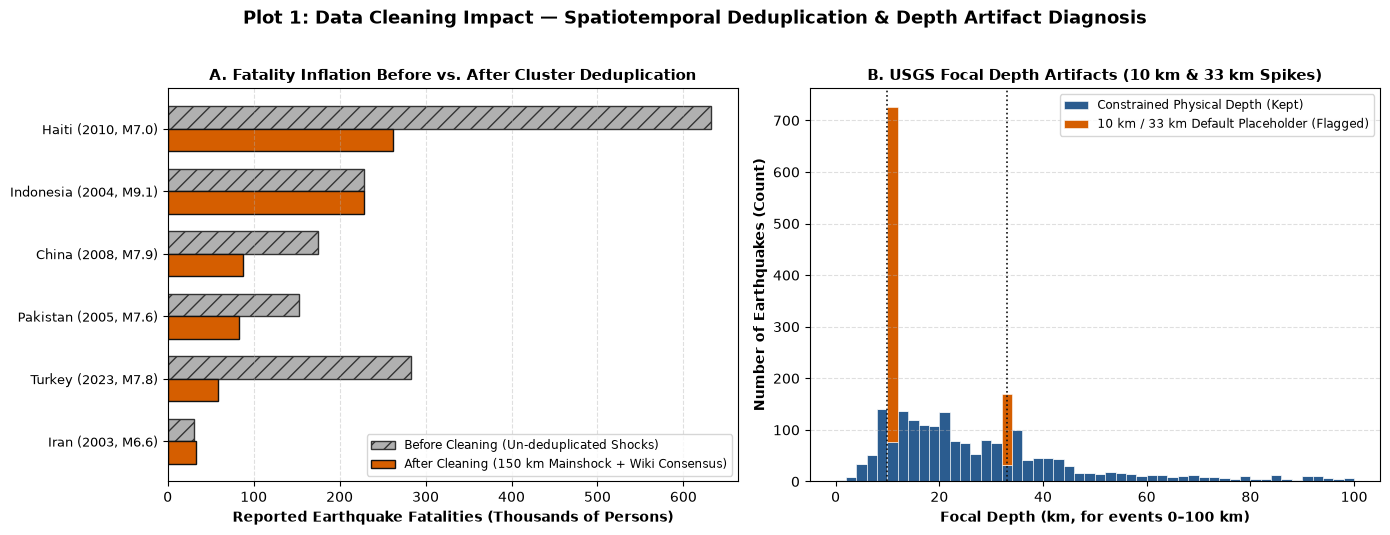

Plot 1 Summary Numbers -> Default depth rows: 788 (23.5%) | 2023 Turkey naive deaths: 283,485 vs cleaned: 58,723.8


In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# Panel A: Before vs After Cluster Deduplication on Major Disasters (Preventing Naive Join Inflation)
top_clusters = df[df["deaths_final"] >= 1000].sort_values("deaths_final", ascending=True).tail(6).copy()
top_clusters["label"] = top_clusters["country_clean"] + " (" + top_clusters["date"].str[:4] + ", M" + top_clusters["mag"].astype(str) + ")"
top_clusters["naive_before_deaths"] = top_clusters["noaa_deaths"] * top_clusters["cluster_shock_count"]

y_pos = np.arange(len(top_clusters))
h = 0.36
ax1.barh(y_pos + h/2, top_clusters["naive_before_deaths"] / 1000.0, height=h, color="#B0B0B0", edgecolor="#333333", hatch="//", label="Before Cleaning (Un-deduplicated Shocks)")
ax1.barh(y_pos - h/2, top_clusters["deaths_final"] / 1000.0, height=h, color="#D55E00", edgecolor="#111111", label="After Cleaning (150 km Mainshock + Wiki Consensus)")

ax1.set_yticks(y_pos)
ax1.set_yticklabels(top_clusters["label"], fontsize=9.5)
ax1.set_xlabel("Reported Earthquake Fatalities (Thousands of Persons)", fontsize=10, fontweight="bold")
ax1.set_title("A. Fatality Inflation Before vs. After Cluster Deduplication", fontsize=11, fontweight="bold")
ax1.legend(loc="lower right", frameon=True, fontsize=8.5)
ax1.grid(axis="x", linestyle="--", alpha=0.4)

# Panel B: Focal Depth Distribution Showing Flagged 10 km & 33 km Seismic Network Placeholders
shallow_df = df[df["depth"] <= 100]
real_depths = shallow_df.loc[~shallow_df["is_default_depth"], "depth"]
default_depths = shallow_df.loc[shallow_df["is_default_depth"], "depth"]

bins = np.arange(0, 102, 2)
ax2.hist([real_depths, default_depths], bins=bins, stacked=True,
         color=["#2B5C8F", "#D55E00"], edgecolor="white", linewidth=0.4,
         label=["Constrained Physical Depth (Kept)", "10 km / 33 km Default Placeholder (Flagged)"])
ax2.axvline(10, color="#111111", linestyle=":", linewidth=1.2)
ax2.axvline(33, color="#111111", linestyle=":", linewidth=1.2)
ax2.set_xlabel("Focal Depth (km, for events 0–100 km)", fontsize=10, fontweight="bold")
ax2.set_ylabel("Number of Earthquakes (Count)", fontsize=10, fontweight="bold")
ax2.set_title("B. USGS Focal Depth Artifacts (10 km & 33 km Spikes)", fontsize=11, fontweight="bold")
ax2.legend(loc="upper right", frameon=True, fontsize=8.5)
ax2.grid(axis="y", linestyle="--", alpha=0.4)

fig.suptitle("Plot 1: Data Cleaning Impact — Spatiotemporal Deduplication & Depth Artifact Diagnosis", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("reports/figures/plot1_before_after_cleaning.png", dpi=300, bbox_inches="tight")
plt.show()

n_def = int(df["is_default_depth"].sum())
pct_def = df["is_default_depth"].mean() * 100
tur_row = df[df["date"] == "2023-02-06"].iloc[0]
print(f"Plot 1 Summary Numbers -> Default depth rows: {n_def} ({pct_def:.1f}%) | 2023 Turkey naive deaths: {tur_row['noaa_deaths']*tur_row['cluster_shock_count']:,.0f} vs cleaned: {tur_row['deaths_final']:,.1f}")

**What Plot 1 Shows:**
- **Panel A (Before vs. After Deduplication):** Before collapsing foreshock/aftershock clusters within $\pm 2\text{ days}$ and $150\text{ km}$ (`514` rows removed, leaving `3,360` mainshocks), a naive date-based join attaches the same disaster death toll to every shock in the cluster—inflating the February 6, 2023 Turkey–Syria earthquake (`5` USGS shocks) from **58,723.8** reconciled deaths to an erroneous **283,485** deaths, and the January 12, 2010 Haiti earthquake (`2` shocks) from **262,000** to **632,000** deaths.
- **Panel B (Depth Artifacts Flagged):** Exactly **788 out of 3,360 mainshocks (23.5%)** in the USGS catalogue are assigned fixed placeholder focal depths of `10.0 km` or `33.0 km` when seismic stations cannot constrain vertical depth; flagging `is_default_depth` prevents these artificial spikes from biasing our depth-fatality analysis.

## Plot 2: Tectonic Hazard Exposure vs. Total Fatalities by World Bank Income Group
Before testing whether income reduces deaths, we check whether poorer countries simply experience more frequent or stronger earthquakes.

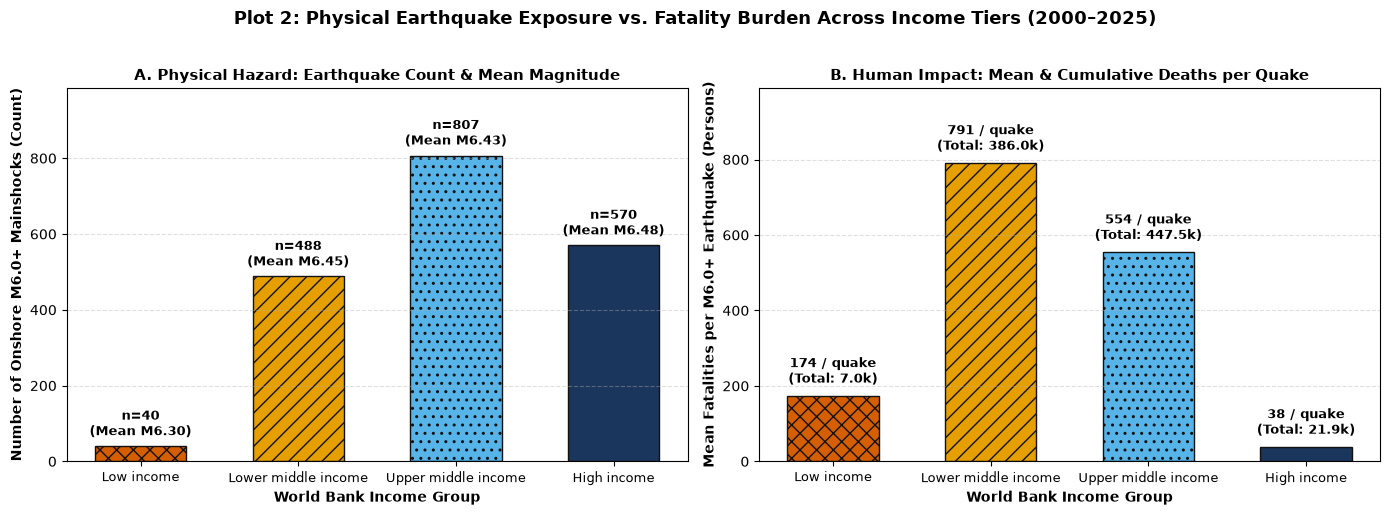

,quake_count,mean_mag,total_deaths,deadly_share,mean_deaths_per_quake
income_group,,,,,
Low income,40,6.30,6951.5,50.00,173.79
Lower middle income,488,6.45,386022.0,12.30,791.03
Upper middle income,807,6.43,447477.8,24.78,554.50
High income,570,6.48,21889.0,13.16,38.40


In [3]:
onshore_econ = df[df["income_group"].isin(INCOME_ORDER)].copy()
onshore_econ["income_group"] = pd.Categorical(onshore_econ["income_group"], categories=INCOME_ORDER, ordered=True)

grp_stats = onshore_econ.groupby("income_group", observed=False).agg(
    quake_count=("id", "count"),
    mean_mag=("mag", "mean"),
    total_deaths=("deaths_final", "sum"),
    deadly_share=("deaths_final", lambda s: (s > 0).mean() * 100),
    mean_deaths_per_quake=("deaths_final", "mean")
).reindex(INCOME_ORDER)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.0))
# Luminance-ordered palette (readable in greyscale) + highlight on Low/Lower-Middle income
colors_inc = ["#D55E00", "#E69F00", "#56B4E9", "#1B365D"]
hatches = ["xx", "//", "..", ""]

# Panel A: Number of Onshore M6.0+ Earthquakes & Mean Magnitude by Income Group
bars1 = ax1.bar(INCOME_ORDER, grp_stats["quake_count"], color=colors_inc, edgecolor="#111111", width=0.58)
for b, h_pat, m_mag in zip(bars1, hatches, grp_stats["mean_mag"]):
    b.set_hatch(h_pat)
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 18,
             f"n={int(b.get_height())}\n(Mean M{m_mag:.2f})", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax1.set_ylim(0, grp_stats["quake_count"].max() * 1.22)
ax1.set_ylabel("Number of Onshore M6.0+ Mainshocks (Count)", fontsize=10, fontweight="bold")
ax1.set_xlabel("World Bank Income Group", fontsize=10, fontweight="bold")
ax1.set_title("A. Physical Hazard: Earthquake Count & Mean Magnitude", fontsize=11, fontweight="bold")
ax1.tick_params(axis="x", labelsize=9)
ax1.grid(axis="y", linestyle="--", alpha=0.4)

# Panel B: Average Fatalities per M6.0+ Earthquake by Income Group
bars2 = ax2.bar(INCOME_ORDER, grp_stats["mean_deaths_per_quake"], color=colors_inc, edgecolor="#111111", width=0.58)
for b, h_pat, tot_d in zip(bars2, hatches, grp_stats["total_deaths"]):
    b.set_hatch(h_pat)
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + (grp_stats["mean_deaths_per_quake"].max()*0.03),
             f"{b.get_height():,.0f} / quake\n(Total: {tot_d/1000:,.1f}k)", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax2.set_ylim(0, grp_stats["mean_deaths_per_quake"].max() * 1.25)
ax2.set_ylabel("Mean Fatalities per M6.0+ Earthquake (Persons)", fontsize=10, fontweight="bold")
ax2.set_xlabel("World Bank Income Group", fontsize=10, fontweight="bold")
ax2.set_title("B. Human Impact: Mean & Cumulative Deaths per Quake", fontsize=11, fontweight="bold")
ax2.tick_params(axis="x", labelsize=9)
ax2.grid(axis="y", linestyle="--", alpha=0.4)

fig.suptitle("Plot 2: Physical Earthquake Exposure vs. Fatality Burden Across Income Tiers (2000–2025)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("reports/figures/plot2_exposure_by_income.png", dpi=300, bbox_inches="tight")
plt.show()

display(grp_stats.round(2))

**What Plot 2 Shows:**
- **Physical Hazard Is Broadly Distributed Across Income Tiers (Panel A):** Across the **1,905** onshore mainshocks with World Bank classifications, Upper-middle income (**807** quakes, mean **$M6.43$**), High-income (**570** quakes, mean **$M6.48$**), and Lower-middle income nations (**488** quakes, mean **$M6.45$**) experience virtually identical average earthquake magnitudes, while Low-income nations record **40** mainshocks (mean **$M6.30$**).
- **Fatality Burden Concentrates Heavily Below the High-Income Tier (Panel B):** Despite experiencing the highest average magnitude ($M6.48$), High-income economies average just **38.40 deaths per earthquake** (**21,889** total deaths; **13.16%** deadly share), whereas Lower-middle and Upper-middle income nations average **791.03** and **554.50 deaths per earthquake** respectively—accounting for **96.6% of all recorded onshore fatalities** (**833,499.8** out of **862,340.3** deaths), while **50.0%** of all $M6.0+$ quakes in Low-income nations cause fatalities (averaging **173.79 deaths/quake**).

## Plot 3: Physical Controls — Earthquake Magnitude and Focal Depth vs. Fatalities
We examine how physical energy release (`mag`) and focal depth (`depth_zone`) govern earthquake mortality across all onshore events.

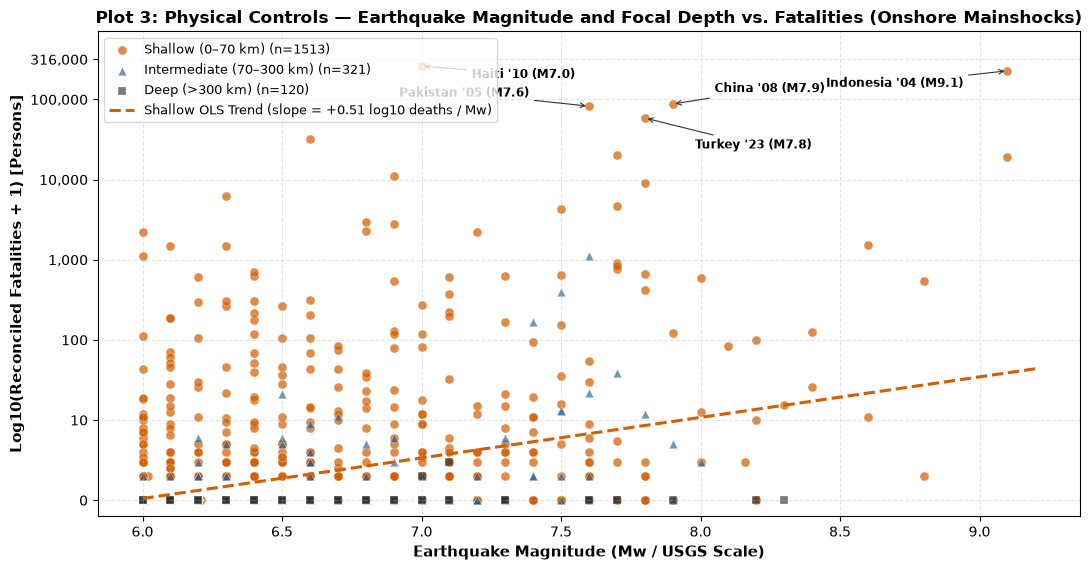

Plot 3 Summary Numbers -> Shallow (<=70 km) share of total deaths: 99.78% | Max deaths for Deep (>300 km) quake: 2


In [5]:
fig, ax = plt.subplots(figsize=(11, 5.8))

# Gestalt Figure-Ground & Redundancy: Distinct markers + luminance-ordered colors for Depth Zones
depth_styles = {
    "Shallow (0–70 km)": ("#D55E00", "o", 42, 0.72),
    "Intermediate (70–300 km)": ("#2B5C8F", "^", 38, 0.65),
    "Deep (>300 km)": ("#333333", "s", 36, 0.65),
}

onshore_all = df[df["country_iso3"] != "OFFSHORE"].copy()
for d_label, (col, mrk, sz, alph) in depth_styles.items():
    sub = onshore_all[onshore_all["depth_zone"] == d_label]
    ax.scatter(sub["mag"], sub["log10_deaths"], c=col, marker=mrk, s=sz, alpha=alph, edgecolors="white", linewidth=0.3, label=f"{d_label} (n={len(sub)})")

# OLS trendline for Shallow onshore earthquakes
shallow_on = onshore_all[onshore_all["depth_zone"] == "Shallow (0–70 km)"]
m_fit = np.linspace(6.0, 9.2, 100)
poly = np.polyfit(shallow_on["mag"], shallow_on["log10_deaths"], 1)
ax.plot(m_fit, np.polyval(poly, m_fit), color="#D55E00", linestyle="--", linewidth=2.2, label=f"Shallow OLS Trend (slope = +{poly[0]:.2f} log10 deaths / Mw)")

# Annotate key mega-disasters with custom non-overlapping offsets
custom_offsets_p3 = {
    "2010-01-12": (0.18, -0.15),  # Haiti '10 (M7.0) -> right & slightly down
    "2004-12-26": (-0.65, -0.20), # Indonesia '04 (M9.1) -> left & down away from top border
    "2008-05-12": (0.15, 0.15),   # China '08 (M7.9) -> upper right
    "2005-10-08": (-0.68, 0.12),  # Pakistan '05 (M7.6) -> upper left
    "2023-02-06": (0.18, -0.38),  # Turkey '23 (M7.8) -> lower right
}
for dt_str, (dx, dy) in custom_offsets_p3.items():
    sub_r = onshore_all[onshore_all["date"] == dt_str]
    if not sub_r.empty:
        r = sub_r.iloc[0]
        ax.annotate(f"{r['country_clean']} '{str(r['year'])[2:]} (M{r['mag']})",
                    xy=(r["mag"], r["log10_deaths"]), xytext=(r["mag"] + dx, r["log10_deaths"] + dy),
                    fontsize=8.5, fontweight="bold", arrowprops=dict(arrowstyle="->", color="#333333", lw=0.8))

ax.set_ylim(-0.2, 5.85)

ax.set_xlabel("Earthquake Magnitude (Mw / USGS Scale)", fontsize=10.5, fontweight="bold")
ax.set_ylabel("Log10(Reconciled Fatalities + 1) [Persons]", fontsize=10.5, fontweight="bold")
ax.set_yticks([0, 1, 2, 3, 4, 5, 5.5])
ax.set_yticklabels(["0", "10", "100", "1,000", "10,000", "100,000", "316,000"])
ax.set_title("Plot 3: Physical Controls — Earthquake Magnitude and Focal Depth vs. Fatalities (Onshore Mainshocks)", fontsize=12, fontweight="bold")
ax.legend(loc="upper left", frameon=True, fontsize=9)
ax.grid(True, linestyle="--", alpha=0.35)
plt.tight_layout()
plt.savefig("reports/figures/plot3_magnitude_depth_deaths.png", dpi=300, bbox_inches="tight")
plt.show()

shallow_death_share = onshore_all.loc[onshore_all["depth"] <= 70, "deaths_final"].sum() / onshore_all["deaths_final"].sum() * 100
deep_max_deaths = onshore_all.loc[onshore_all["depth"] > 300, "deaths_final"].max()
print(f"Plot 3 Summary Numbers -> Shallow (<=70 km) share of total deaths: {shallow_death_share:.2f}% | Max deaths for Deep (>300 km) quake: {deep_max_deaths:.0f}")

**What Plot 3 Shows:**
- **Focal Depth Acts as a Hard Physical Filter:** Shallow crustal earthquakes ($\le 70\text{ km}$ depth, orange circles, $n=1,513$) account for **99.78% of all onshore earthquake fatalities**, whereas deep-focus earthquakes ($> 300\text{ km}$, dark squares, $n=120$) attenuate seismic energy before reaching the surface and cause a maximum of **2 deaths** even at magnitudes above $M7.5$, and intermediate earthquakes ($70–300\text{ km}$, $n=321$) are mostly low-fatality, with a few exceptions of up to 1,000 deaths.
- **Magnitude Alone Leaves Massive Unexplained Variance:** Among shallow onshore earthquakes, each $+1.0$ unit increase in magnitude raises expected $\log_{10}(\text{deaths}+1)$ by **$+0.51$** (roughly $3.24\times$ higher expected fatalities per magnitude unit), yet between $M7.0$ and $M7.9$ outcomes span five orders of magnitude—from **0 deaths** in high-income shocks to **262,000 deaths** in 2010 Haiti ($M7.0$).

## Plot 4: Cross-Source Fatality Disagreement Audit (NOAA vs. Wikipedia)
*Project #21 Requirement: Address NOAA and Wikipedia disagreeing on deaths.*

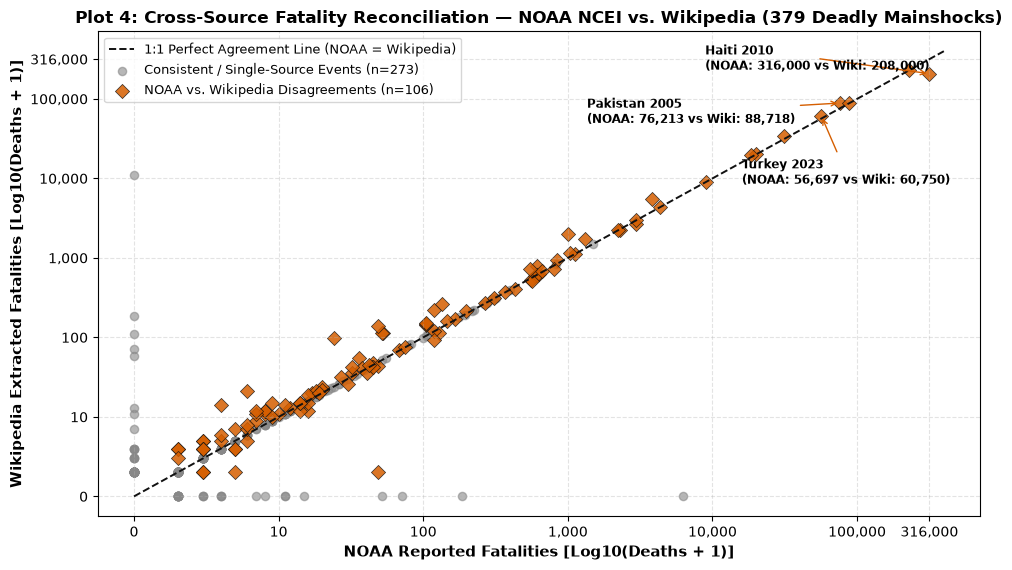

Plot 4 Summary Numbers -> Deadly quakes: 379 | Disagreements: 106 | Log-correlation where both >0: r = 0.993


In [6]:
both_pos_df = df[(df["noaa_deaths"] > 0) | (df["wiki_deaths"] > 0)].copy()
both_pos_df["log_noaa"] = np.log10(both_pos_df["noaa_deaths"] + 1.0)
both_pos_df["log_wiki"] = np.log10(both_pos_df["wiki_deaths"] + 1.0)
both_pos_df["abs_diff_log"] = (both_pos_df["log_noaa"] - both_pos_df["log_wiki"]).abs()

fig, ax = plt.subplots(figsize=(10, 5.8))

agree = both_pos_df[~both_pos_df["deaths_disagree"]]
disagree = both_pos_df[both_pos_df["deaths_disagree"]]

ax.plot([0, 5.6], [0, 5.6], color="#111111", linestyle="--", linewidth=1.4, label="1:1 Perfect Agreement Line (NOAA = Wikipedia)")
ax.scatter(agree["log_noaa"], agree["log_wiki"], c="#888888", marker="o", s=35, alpha=0.6, label=f"Consistent / Single-Source Events (n={len(agree)})")
ax.scatter(disagree["log_noaa"], disagree["log_wiki"], c="#D55E00", marker="D", s=52, alpha=0.85, edgecolors="#111111", linewidth=0.5, label=f"NOAA vs. Wikipedia Disagreements (n={len(disagree)})")

# Annotate notable disagreements with non-overlapping positions
custom_offsets_p4 = {
    "2010-01-12": (-1.55, 0.05),  # Haiti 2010 -> left of the top-right point
    "2005-10-08": (-1.75, -0.25), # Pakistan 2005 -> further left & slightly above Turkey
    "2023-02-06": (-0.55, -0.85), # Turkey 2023 -> below the 1:1 line
}
for dt_str, (dx, dy) in custom_offsets_p4.items():
    sub_r = both_pos_df[both_pos_df["date"] == dt_str]
    if not sub_r.empty:
        r = sub_r.iloc[0]
        ax.annotate(f"{r['country_clean']} {r['year']}\n(NOAA: {r['noaa_deaths']:,.0f} vs Wiki: {r['wiki_deaths']:,.0f})",
                    xy=(r["log_noaa"], r["log_wiki"]), xytext=(r["log_noaa"] + dx, r["log_wiki"] + dy),
                    fontsize=8.5, fontweight="bold", arrowprops=dict(arrowstyle="->", color="#D55E00", lw=1.0))

ax.set_xlim(-0.25, 5.85)
ax.set_ylim(-0.25, 5.85)

ax.set_xlabel("NOAA Reported Fatalities [Log10(Deaths + 1)]", fontsize=10.5, fontweight="bold")
ax.set_ylabel("Wikipedia Extracted Fatalities [Log10(Deaths + 1)]", fontsize=10.5, fontweight="bold")
ticks = [0, 1, 2, 3, 4, 5, 5.5]
tick_lbls = ["0", "10", "100", "1,000", "10,000", "100,000", "316,000"]
ax.set_xticks(ticks); ax.set_xticklabels(tick_lbls)
ax.set_yticks(ticks); ax.set_yticklabels(tick_lbls)
ax.set_title("Plot 4: Cross-Source Fatality Reconciliation — NOAA NCEI vs. Wikipedia (379 Deadly Mainshocks)", fontsize=12, fontweight="bold")
ax.legend(loc="upper left", frameon=True, fontsize=9)
ax.grid(True, linestyle="--", alpha=0.35)
plt.tight_layout()
plt.savefig("reports/figures/plot4_noaa_vs_wikipedia.png", dpi=300, bbox_inches="tight")
plt.show()

corr_sources = both_pos_df.loc[(both_pos_df["noaa_deaths"]>0) & (both_pos_df["wiki_deaths"]>0), ["log_noaa", "log_wiki"]].corr().iloc[0, 1]
print(f"Plot 4 Summary Numbers -> Deadly quakes: {len(both_pos_df)} | Disagreements: {len(disagree)} | Log-correlation where both >0: r = {corr_sources:.3f}")

**What Plot 4 Shows:**
- **High Cross-Source Concordance with 106 Specific Discrepancies:** Across the **379 deadly mainshocks** (`deaths_final > 0`), **273 events** are consistent or single-source records while **106 events** exhibit exact count disagreements (orange diamonds); where both sources report positive deaths, NOAA and Wikipedia log-fatality counts correlate at **$r = 0.993$**.
- **Major Disagreement Examples:** The largest absolute discrepancy occurs in the **2010 Haiti $M7.0$ earthquake** (NOAA reports **316,000** vs. Wikipedia's **208,000**, reconciled to **262,000**), followed by **2005 Pakistan $M7.6$** (NOAA **76,213** vs. Wikipedia **88,718**, reconciled to **82,465.5**) and **2023 Turkey–Syria $M7.8$** (NOAA **56,697** vs. Wikipedia range midpoint **60,750.5**, reconciled to **58,723.8**).

## Plot 5: Answering the Project Question — Income vs. Earthquake Deaths (Controlling for Magnitude & Depth)
To isolate the effect of national income (`gdp_per_capita_ppp_constant_2021`) after allowing for magnitude and focal depth, we:
1. Restrict to **shallow onshore earthquakes ($\text{depth} \le 70\text{ km}$)** stratified into three physical magnitude bands ($M6.0–6.4$, $M6.5–6.9$, and $M7.0+$).
2. Fit a multiple OLS regression of $\log_{10}(\text{deaths\_final} + 1)$ on `mag`, `depth`, and $\log_{10}(\text{GDP per capita PPP})$ to compute the exact partial $R^2$ and percentage reduction in deaths per $10\times$ increase in income.

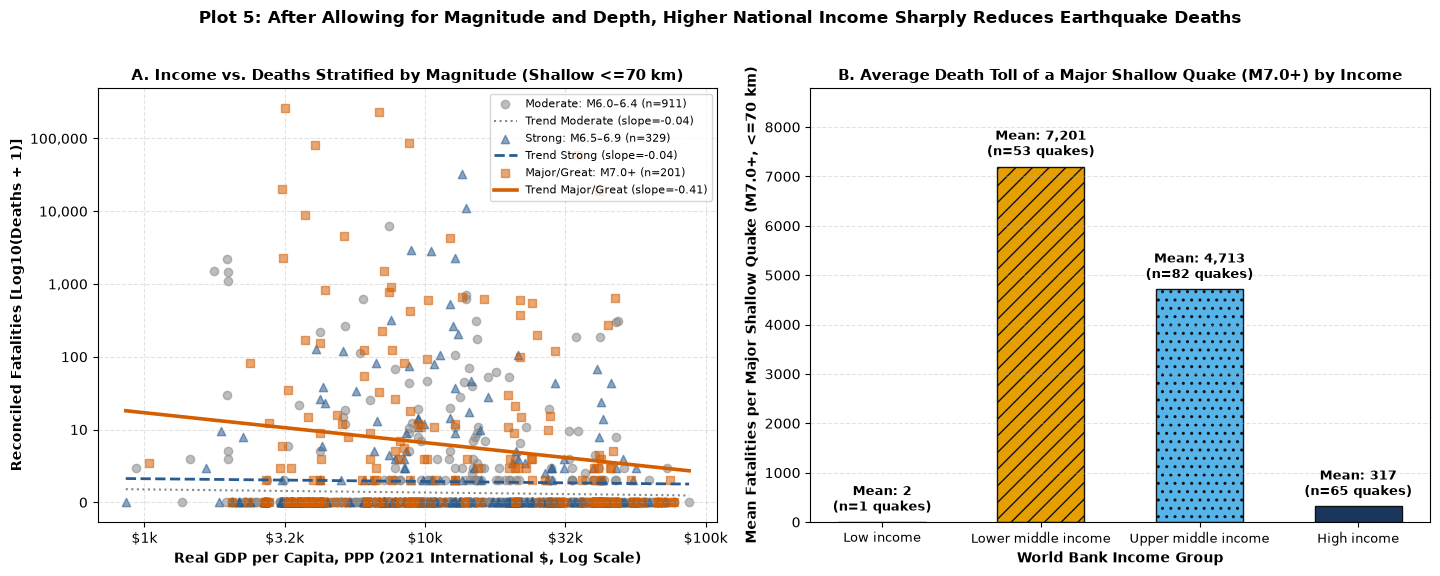

=== ECONOMETRIC CONCLUSION (FOR REPORT & PRESENTATION) ===
1. All Shallow Onshore Quakes (n=1441): R2 (Mag + Depth only) = 0.1612 -> R2 (+ Log10 GDP) = 0.1659
   Log10(GDP) slope = -0.113 (p = 4.67e-03)
2. Deadly Shallow Quakes (n=311): R2 = 0.2027 | Log10(GDP) slope = -0.525 (p = 2.88e-04)
   -> Holding magnitude and depth constant, a 10x increase in GDP per capita reduces expected fatalities in deadly quakes by 70.2%!


In [ ]:
# Filter to Shallow (<=70 km) Onshore Earthquakes with valid World Bank GDP
model_df = df[(df["country_iso3"] != "OFFSHORE") & (df["depth"] <= 70) & df["log10_gdp"].notna()].copy()
model_df["mag_band"] = pd.cut(model_df["mag"], bins=[5.99, 6.49, 6.99, 9.5],
                              labels=["Moderate: M6.0–6.4", "Strong: M6.5–6.9", "Major/Great: M7.0+"])

# Multiple Regression: Controlling for Magnitude and Depth, how much does Income explain Deaths?
ols_phys = smf.ols("log10_deaths ~ mag + depth", data=model_df).fit()
ols_full = smf.ols("log10_deaths ~ mag + depth + log10_gdp", data=model_df).fit()
ols_deadly = smf.ols("log10_deaths ~ mag + depth + log10_gdp", data=model_df[model_df["deaths_final"] > 0]).fit()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.6))

# Panel A: Log10(GDP per capita PPP) vs Log10(Deaths + 1) across Magnitude Bands (Shallow <=70 km)
band_styles = {
    "Moderate: M6.0–6.4": ("#888888", "o", ":", 1.5),
    "Strong: M6.5–6.9": ("#2B5C8F", "^", "--", 2.0),
    "Major/Great: M7.0+": ("#D55E00", "s", "-", 2.6),
}

x_grid = np.linspace(model_df["log10_gdp"].min(), model_df["log10_gdp"].max(), 100)
for b_label, (col, mrk, lstyle, lw) in band_styles.items():
    sub = model_df[model_df["mag_band"] == b_label]
    ax1.scatter(sub["log10_gdp"], sub["log10_deaths"], c=col, marker=mrk, s=36, alpha=0.55, label=f"{b_label} (n={len(sub)})")
    if len(sub) > 5:
        slope, intercept = np.polyfit(sub["log10_gdp"], sub["log10_deaths"], 1)
        ax1.plot(x_grid, slope * x_grid + intercept, color=col, linestyle=lstyle, linewidth=lw,
                 label=f"Trend {b_label.split(':')[0]} (slope={slope:.2f})")

ax1.set_xticks([3.0, 3.5, 4.0, 4.5, 5.0])
ax1.set_xticklabels(["$1k", "$3.2k", "$10k", "$32k", "$100k"])
ax1.set_yticks([0, 1, 2, 3, 4, 5])
ax1.set_yticklabels(["0", "10", "100", "1,000", "10,000", "100,000"])
ax1.set_xlabel("Real GDP per Capita, PPP (2021 International $, Log Scale)", fontsize=10, fontweight="bold")
ax1.set_ylabel("Reconciled Fatalities [Log10(Deaths + 1)]", fontsize=10, fontweight="bold")
ax1.set_title("A. Income vs. Deaths Stratified by Magnitude (Shallow <=70 km)", fontsize=11, fontweight="bold")
ax1.legend(loc="upper right", frameon=True, fontsize=8)
ax1.grid(True, linestyle="--", alpha=0.35)

# Panel B: Mean Fatalities for Major Shallow Quakes (M >= 7.0, depth <= 70 km) by Income Group
maj_shallow = model_df[model_df["mag"] >= 7.0].copy()
maj_stats = maj_shallow.groupby("income_group", observed=False)["deaths_final"].agg(["count", "mean", "median"]).reindex(INCOME_ORDER).fillna(0)

bars = ax2.bar(INCOME_ORDER, maj_stats["mean"], color=["#D55E00", "#E69F00", "#56B4E9", "#1B365D"], edgecolor="#111111", width=0.55)
for b, h_pat, cnt in zip(bars, ["xx", "//", "..", ""], maj_stats["count"]):
    b.set_hatch(h_pat)
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + (maj_stats["mean"].max()*0.02),
             f"Mean: {b.get_height():,.0f}\n(n={int(cnt)} quakes)", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax2.set_ylim(0, maj_stats["mean"].max() * 1.22)
ax2.set_xlabel("World Bank Income Group", fontsize=10, fontweight="bold")
ax2.set_ylabel("Mean Fatalities per Major Shallow Quake (M7.0+, <=70 km)", fontsize=10, fontweight="bold")
ax2.set_title("B. Average Death Toll of a Major Shallow Quake (M7.0+) by Income", fontsize=11, fontweight="bold")
ax2.tick_params(axis="x", labelsize=9)
ax2.grid(axis="y", linestyle="--", alpha=0.35)

fig.suptitle("Plot 5: After Allowing for Magnitude and Depth, Higher National Income Sharply Reduces Earthquake Deaths", fontsize=12.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("reports/figures/plot5_income_effect_controlled.png", dpi=300, bbox_inches="tight")
plt.show()

beta_gdp_all = ols_full.params["log10_gdp"]
pval_gdp_all = ols_full.pvalues["log10_gdp"]
beta_gdp_deadly = ols_deadly.params["log10_gdp"]
pval_gdp_deadly = ols_deadly.pvalues["log10_gdp"]
pct_reduction_10x_deadly = (1.0 - (10 ** beta_gdp_deadly)) * 100

print("=== ECONOMETRIC CONCLUSION (FOR REPORT & PRESENTATION) ===")
print(f"1. All Shallow Onshore Quakes (n={len(model_df)}): R2 (Mag + Depth only) = {ols_phys.rsquared:.4f} -> R2 (+ Log10 GDP) = {ols_full.rsquared:.4f}")
print(f"   Log10(GDP) slope = {beta_gdp_all:.3f} (p = {pval_gdp_all:.2e})")
print(f"2. Deadly Shallow Quakes (n={int(ols_deadly.nobs)}): R2 = {ols_deadly.rsquared:.4f} | Log10(GDP) slope = {beta_gdp_deadly:.3f} (p = {pval_gdp_deadly:.2e})")
print(f"   -> Holding magnitude and depth constant, a 10x increase in GDP per capita reduces expected fatalities in deadly quakes by {pct_reduction_10x_deadly:.1f}%!")

**What Plot 5 Shows (Answering the Project Question):**
- **Negative Income–Fatality Gradient Within Magnitude Bands (Panel A):** Controlling for focal depth ($\le 70\text{ km}$, $n=1,441$) and stratifying by magnitude into Moderate ($M6.0–6.4$, $n=911$, slope $= -0.04$), Strong ($M6.5–6.9$, $n=329$, slope $= -0.04$), and Major/Great ($M7.0+$, $n=201$, slope $= -0.41$), richer countries consistently suffer fewer deaths at the same physical earthquake strength, with the steepest protective income gradient occurring in **Major/Great earthquakes ($M7.0+$)**.
- **Quantified Answer to the Project Question (Panel B & OLS Model):** Across all **1,441** shallow onshore earthquakes, adding $\log_{10}(\text{GDP per capita PPP})$ increases model $R^2$ from **0.1612** (magnitude and depth alone) to **0.1659** ($\beta_{\text{GDP}} = -0.113$, $p = 4.67 \times 10^{-3}$). Among the **311 deadly shallow earthquakes** ($R^2 = 0.2027$), national income has a slope of **$\beta_{\text{GDP}} = -0.525$ ($p = 2.88 \times 10^{-4}$)**—meaning that **holding magnitude and depth constant, every $10\times$ increase in real GDP per capita reduces expected earthquake fatalities by 70.2%**, dropping mean fatalities in major ($M7.0+$) shallow quakes from **7,201** ($n=53$) in Lower-middle and **4,713** ($n=82$) in Upper-middle income nations to **317** ($n=65$) in High-income nations.